# 2. P-FFA search over acceleration and frequency

A pulsar in a binary orbit has a line-of-sight acceleration, so its
apparent spin frequency drifts during the observation. Folding at a
constant frequency smears the pulse. Here loki's P-FFA searches a 2-D grid
of (acceleration, frequency), folding every trial along a quadratic phase
track. Both shift modes (time and Fourier domain, see notebook 1) run on
the same data.

Runtime: about 10 seconds; memory: about 6 GB.

In [1]:
%matplotlib inline
from matplotlib import pyplot as plt

from loki import libloki
from loki.libloki.configs import PulsarSearchConfig
from loki.search import ffa_search
from pyloki.config import ParamLimits
from pyloki.simulation.pulse import PulseSignalConfig

libloki.set_log_level("warning")  # hide loki's per-step info messages
SEED = 1
NTHREADS = 4  # CPU threads; raise it on a machine of your own

## Simulated data

A 7 ms pulsar with a constant acceleration of 200 m/s², a pulse of 10 %
duty cycle and a folded S/N of 10, in 2^23 samples of 64 µs (about 9
minutes). The first plot folds at the true spin frequency only, the
second also removes the acceleration: the curved track straightens.

T_obs = 536.9 s, true frequency = 142.857143 Hz


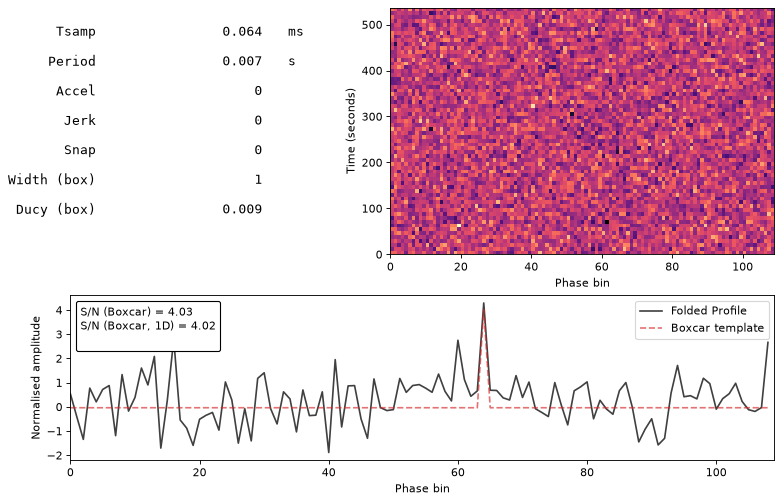

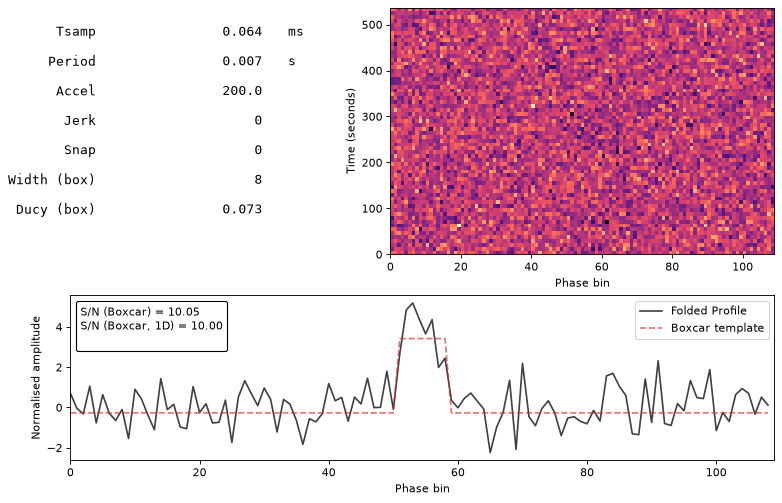

In [2]:
accel = 200.0
mod_kwargs = {"acc": accel}
cfg = PulseSignalConfig(
    period=0.007,
    dt=64e-6,
    nsamps=2**23,
    snr=10,
    ducy=0.1,
    mod_kwargs=mod_kwargs,
    seed=SEED,
)
tim_data = cfg.generate(shape="gaussian")
print(f"T_obs = {cfg.tobs:.1f} s, true frequency = {cfg.freq:.6f} Hz")
tim_data.plot_fold(cfg.freq, cfg.fold_bins, dpi=80)
plt.show()
tim_data.plot_fold(cfg.freq, cfg.fold_bins, mod_kwargs=mod_kwargs, dpi=80)
plt.show()

## Search configuration

`ParamLimits.from_upper` sets the acceleration range to ±1000 m/s² and
widens the frequency interval around the spin frequency by the largest
Doppler shift that range can cause. Limits are ordered from the highest
derivative down to frequency.

In [3]:
limits = ParamLimits.from_upper(cfg.freq, [accel], (-1000.0, 1000.0), cfg.tobs)
print("accel (m/s^2):", limits.limits[0])
print("freq (Hz):    ", limits.limits[1])


def search_config(use_fourier: bool) -> PulsarSearchConfig:
    return PulsarSearchConfig(
        nsamps=cfg.nsamps,
        tsamp=cfg.dt,
        nbins=64,
        eta=1,
        param_limits=limits.limits,
        bseg_brute=cfg.nsamps // 16384,
        ducy_max=0.2,
        wtsp=1.5,
        nthreads=NTHREADS,
        use_fourier=use_fourier,
    )


true_values = {"accel": accel, "freq": cfg.freq}
results = {}
for use_fourier in (False, True):
    mode = "Fourier" if use_fourier else "time"
    plan, pgram = ffa_search(tim_data, search_config(use_fourier))
    results[mode] = pgram
    print(f"--- {mode} domain: {pgram.snrs.size:,} trials (accel x freq x width)")
    print(pgram.get_indices_summary(true_values=true_values))
    print(pgram.get_summary())

accel (m/s^2): [-1000.  1000.]
freq (Hz):     [142.72922796 142.98505776]


--- time domain: 33,849,200 trials (accel x freq x width)
True param indices: (659, 2197)
Best param indices: (np.int64(660), np.int64(2197), np.int64(4))
Best S/N: 9.26
Best Period: 0.007000001425803317
Best accel: 200.9090909090909
Best freq: 142.85711375912192
Best width: 6


--- Fourier domain: 33,849,200 trials (accel x freq x width)
True param indices: (659, 2197)
Best param indices: (np.int64(660), np.int64(2198), np.int64(3))
Best S/N: 9.47
Best Period: 0.006999998574197266
Best accel: 200.9090909090909
Best freq: 142.85717195516378
Best width: 4


## Periodograms

The best S/N over widths along frequency and acceleration, and across the
acceleration-frequency plane (time domain; the last plot is the plane in
the Fourier mode). Acceleration and frequency are correlated: a wrong
acceleration is partly compensated by a shifted frequency, which tilts
the peak.

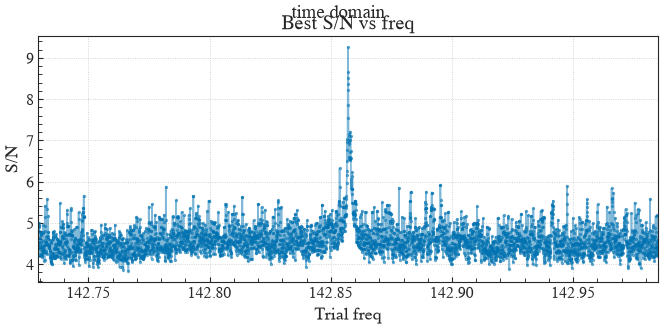

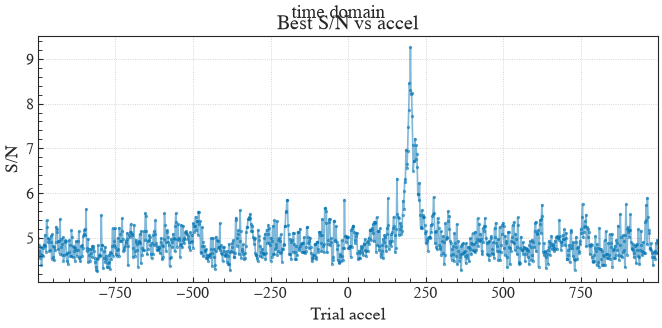

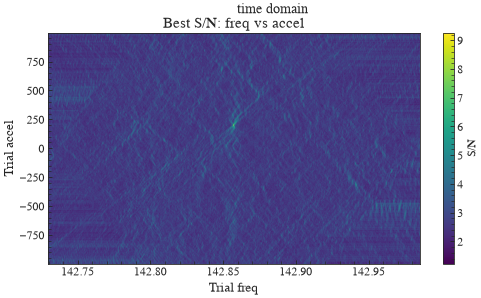

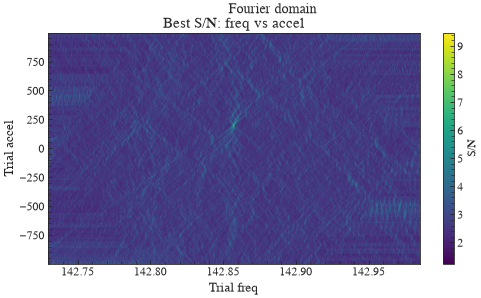

In [4]:
pgram = results["time"]
for param in ("freq", "accel"):
    fig = pgram.plot_1d(param, figsize=(10, 4), dpi=80)
    fig.suptitle("time domain")
    plt.show()
for mode, pgram in results.items():
    fig = pgram.plot_2d("freq", "accel", figsize=(10, 5), dpi=60)
    fig.suptitle(f"{mode} domain")
    plt.show()

## Time vs Fourier domain

Both modes recover the pulsar within one grid step of the true
parameters.

In [5]:
print(f"{'mode':>8}  {'best S/N':>8}  {'accel error':>11}  {'freq error (Hz)':>15}")
for mode, pgram in results.items():
    best = pgram.find_best_params()
    print(
        f"{mode:>8}  {best['snr']:8.2f}  {best['accel'] - accel:11.2f}  "
        f"{best['freq'] - cfg.freq:15.2e}",
    )

    mode  best S/N  accel error  freq error (Hz)
    time      9.26         0.91        -2.91e-05
 Fourier      9.47         0.91         2.91e-05
